# Notebook 08A — Model Stability, Signal and Shrinkage Diagnostics

**Project:** WR-MovementIQ  
**Purpose:** Diagnose the existing nested Ridge results without changing the analysis sample, refitting the primary experiment, or overwriting prior outputs.

This notebook uses the frozen 93-row / 54-receiver core dataset and the existing Notebook 08 outputs. It investigates predictor variation and redundancy, outcome variation, out-of-fold calibration and shrinkage, residual patterns, receiver-level error concentration, cohort performance, and Ridge alpha selection.

**Important:** This is a diagnostic notebook, not a new model-selection exercise. It does not claim causal relationships. It does not alter the primary modelling results. Where an artifact does not contain enough information to support a diagnostic, the notebook reports that limitation rather than guessing.

## 1. Environment and project paths

In [1]:
from pathlib import Path
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data/features/wr_analysis_dataset_core_common.parquet"
REPORT_DIR = PROJECT_ROOT / "reports/nested_ridge_modeling"
DESIGN_DIR = PROJECT_ROOT / "reports/modeling_design"
OUT_DIR = PROJECT_ROOT / "reports/model_stability"
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "oof": REPORT_DIR / "oof_predictions.csv",
    "inner_tuning": REPORT_DIR / "inner_tuning_results.csv",
    "loco_predictions": REPORT_DIR / "loco_predictions.csv",
    "loco_metrics": REPORT_DIR / "loco_metrics.csv",
    "alpha_diagnostics": REPORT_DIR / "alpha_diagnostics.csv",
    "manifest": REPORT_DIR / "modeling_manifest.json",
    "design_manifest": DESIGN_DIR / "modeling_design_manifest.json",
}

missing = [str(p) for p in [DATA_PATH, *FILES.values()] if not p.exists()]
if missing:
    raise FileNotFoundError("Required project artifacts are missing:\n" + "\n".join(missing))

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUT_DIR)

Project root: D:\PROJECTS\WR-MovementIQ
Output directory: D:\PROJECTS\WR-MovementIQ\reports\model_stability


## 2. Load and verify the frozen dataset and modelling artifacts

In [2]:
df = pd.read_parquet(DATA_PATH)
oof = pd.read_csv(FILES["oof"])
inner = pd.read_csv(FILES["inner_tuning"])
loco_pred = pd.read_csv(FILES["loco_predictions"])
loco_metrics = pd.read_csv(FILES["loco_metrics"])
alpha_diag = pd.read_csv(FILES["alpha_diagnostics"])

with open(FILES["manifest"], "r", encoding="utf-8") as f:
    model_manifest = json.load(f)
with open(FILES["design_manifest"], "r", encoding="utf-8") as f:
    design_manifest = json.load(f)

sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
expected_sha = design_manifest.get("core_dataset_sha256")
assert sha == expected_sha, f"Dataset fingerprint mismatch: {sha} != {expected_sha}"
assert len(df) == 93 and df["nfl_id"].nunique() == 54
assert len(oof) > 0
required_oof = {"outcome","model","nfl_id","season","draft_year","outer_fold","actual","predicted"}
assert required_oof.issubset(oof.columns), required_oof - set(oof.columns)

print("Dataset:", df.shape, "| receivers:", df.nfl_id.nunique())
print("OOF predictions:", oof.shape)
print("Inner tuning:", inner.shape)
print("LOCO predictions:", loco_pred.shape)
print("LOCO metrics:", loco_metrics.shape)
print("SHA256 verified:", sha)
print("\nOOF models:", sorted(oof.model.dropna().unique()))
print("OOF outcomes:", sorted(oof.outcome.dropna().unique()))
print("Inner tuning columns:", inner.columns.tolist())

Dataset: (93, 103) | receivers: 54
OOF predictions: (2232, 9)
Inner tuning: (90, 10)
LOCO predictions: (2232, 8)
LOCO metrics: (72, 8)
SHA256 verified: 02fbd802522973f7c4d100da57cd680f7bbfde6346a0431a7aa1fe5e25807c5c

OOF models: ['BASELINE', 'COMBINED', 'TRACKING', 'TRADITIONAL']
OOF outcomes: ['game_mean_acceleration_raw_median', 'game_mean_speed_raw_median', 'game_p95_speed_raw_median', 'game_path_efficiency_median', 'game_peak_acceleration_raw_median', 'game_peak_speed_raw_median']
Inner tuning columns: ['outcome', 'model', 'outer_fold', 'best_alpha', 'inner_best_mae', 'train_rows', 'test_rows', 'train_players', 'test_players', 'alpha_at_grid_boundary']


## 3. Define the analysis variables

In [3]:
OUTCOMES = [
    "game_mean_speed_raw_median",
    "game_peak_speed_raw_median",
    "game_p95_speed_raw_median",
    "game_mean_acceleration_raw_median",
    "game_peak_acceleration_raw_median",
    "game_path_efficiency_median",
]
TRADITIONAL = ["forty", "vertical", "broad_jump"]
TRACKING = [
    "combine_mean_speed_median_across_drills",
    "combine_peak_speed_median_across_drills",
    "combine_p95_speed_median_across_drills",
    "combine_mean_acceleration_median_across_drills",
    "combine_peak_acceleration_median_across_drills",
    "combine_path_efficiency_median_across_drills",
]
FEATURES = TRADITIONAL + TRACKING
KEYS = ["draft_year", "nfl_id", "season"]

for c in OUTCOMES + FEATURES:
    if c not in df.columns:
        print("Not present in core dataset:", c)

available_features = [c for c in FEATURES if c in df.columns]
available_outcomes = [c for c in OUTCOMES if c in df.columns]
assert len(available_features) > 0 and len(available_outcomes) > 0

print("Available predictors:", len(available_features))
print("Available outcomes:", len(available_outcomes))

Available predictors: 9
Available outcomes: 6


## 4. Predictor distributions, missingness and variation

In [4]:
feature_rows = []
for col in available_features:
    x = pd.to_numeric(df[col], errors="coerce")
    feature_rows.append({
        "feature": col, "n": int(x.notna().sum()), "missing": int(x.isna().sum()),
        "unique_values": int(x.nunique()), "mean": x.mean(), "std": x.std(),
        "min": x.min(), "p25": x.quantile(.25), "median": x.median(),
        "p75": x.quantile(.75), "max": x.max(),
        "coefficient_of_variation": (x.std()/abs(x.mean())) if pd.notna(x.mean()) and x.mean()!=0 else np.nan
    })
feature_summary = pd.DataFrame(feature_rows)
display(feature_summary)
feature_summary.to_csv(OUT_DIR / "predictor_distributions.csv", index=False)

missingness = df[available_features].isna().sum().rename("missing_count").to_frame()
missingness["missing_pct"] = missingness["missing_count"] / len(df) * 100
display(missingness)
missingness.to_csv(OUT_DIR / "predictor_missingness.csv")

,feature,n,missing,unique_values,mean,std,min,p25,median,p75,max,coefficient_of_variation
0,forty,93,0,28,4.465269,0.080886,4.300000,4.400000,4.450000,4.510000,4.690000,0.018115
1,vertical,93,0,20,37.747312,2.660729,29.000000,36.000000,38.000000,39.500000,42.500000,0.070488
2,broad_jump,93,0,20,126.440860,4.633203,116.000000,124.000000,127.000000,129.000000,136.000000,0.036643
3,combine_mean_speed_median_across_drills,93,0,54,5.686593,0.314339,4.898461,5.484146,5.681765,5.916272,6.406196,0.055277
4,combine_peak_speed_median_across_drills,93,0,53,8.294605,0.223605,7.840000,8.140000,8.303333,8.483333,8.698245,0.026958
5,combine_p95_speed_median_across_drills,93,0,54,8.186691,0.200977,7.761000,8.053333,8.199333,8.332491,8.548327,0.024549
6,combine_mean_acceleration_median_across_drills,93,0,54,3.285356,0.284502,2.604155,3.098788,3.297996,3.487147,3.807039,0.086597
7,combine_peak_acceleration_median_across_drills,93,0,54,6.685642,0.506903,5.200097,6.360050,6.662594,7.107809,7.532192,0.075820
8,combine_path_efficiency_median_across_drills,93,0,54,0.896598,0.018697,0.833971,0.887903,0.898749,0.903483,0.953161,0.020854


,missing_count,missing_pct
forty,0,0.0
vertical,0,0.0
broad_jump,0,0.0
combine_mean_speed_median_across_drills,0,0.0
combine_peak_speed_median_across_drills,0,0.0
combine_p95_speed_median_across_drills,0,0.0
combine_mean_acceleration_median_across_drills,0,0.0
combine_peak_acceleration_median_across_drills,0,0.0
combine_path_efficiency_median_across_drills,0,0.0


## 5. Predictor correlations and redundancy

,forty,vertical,broad_jump,combine_mean_speed_median_across_drills,combine_peak_speed_median_across_drills,combine_p95_speed_median_across_drills,combine_mean_acceleration_median_across_drills,combine_peak_acceleration_median_across_drills,combine_path_efficiency_median_across_drills
forty,1.000,-0.319,-0.280,-0.239,-0.298,-0.326,-0.192,-0.050,-0.044
vertical,-0.319,1.000,0.644,0.037,-0.097,-0.050,-0.000,-0.183,0.090
broad_jump,-0.280,0.644,1.000,-0.019,-0.112,-0.049,-0.009,-0.197,0.112
combine_mean_speed_median_across_drills,-0.239,0.037,-0.019,1.000,0.194,0.242,0.092,-0.085,-0.138
combine_peak_speed_median_across_drills,-0.298,-0.097,-0.112,0.194,1.000,0.970,0.266,0.327,-0.179
combine_p95_speed_median_across_drills,-0.326,-0.050,-0.049,0.242,0.970,1.000,0.273,0.323,-0.133
combine_mean_acceleration_median_across_drills,-0.192,-0.000,-0.009,0.092,0.266,0.273,1.000,0.468,-0.405
combine_peak_acceleration_median_across_drills,-0.050,-0.183,-0.197,-0.085,0.327,0.323,0.468,1.000,-0.524
combine_path_efficiency_median_across_drills,-0.044,0.090,0.112,-0.138,-0.179,-0.133,-0.405,-0.524,1.000


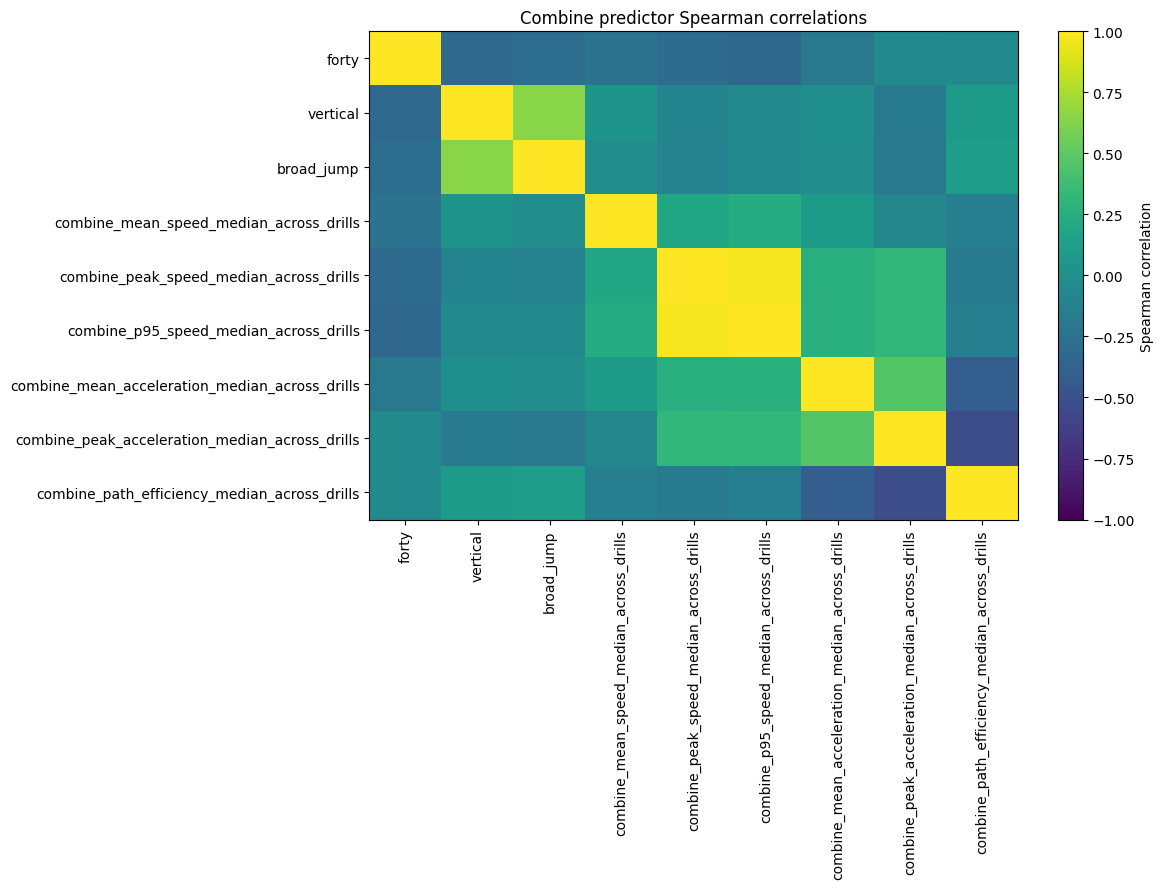

,feature_a,feature_b,spearman_rho,abs_rho
26,combine_peak_speed_median_across_drills,combine_p95_speed_median_across_drills,0.970145,0.970145
8,vertical,broad_jump,0.644162,0.644162
35,combine_peak_acceleration_median_across_drills,combine_path_efficiency_median_across_drills,-0.523581,0.523581
33,combine_mean_acceleration_median_across_drills,combine_peak_acceleration_median_across_drills,0.467888,0.467888
34,combine_mean_acceleration_median_across_drills,combine_path_efficiency_median_across_drills,-0.405104,0.405104
28,combine_peak_speed_median_across_drills,combine_peak_acceleration_median_across_drills,0.327163,0.327163
4,forty,combine_p95_speed_median_across_drills,-0.325811,0.325811
31,combine_p95_speed_median_across_drills,combine_peak_acceleration_median_across_drills,0.323004,0.323004
0,forty,vertical,-0.319364,0.319364
3,forty,combine_peak_speed_median_across_drills,-0.298468,0.298468


In [5]:
corr = df[available_features].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
display(corr.round(3))
corr.to_csv(OUT_DIR / "predictor_spearman_correlations.csv")

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr.values, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Combine predictor Spearman correlations")
fig.tight_layout()
fig.savefig(PLOT_DIR / "predictor_correlation_heatmap.png", dpi=160)
plt.show()

pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i+1:]:
        pairs.append({"feature_a": a, "feature_b": b, "spearman_rho": corr.loc[a,b],
                      "abs_rho": abs(corr.loc[a,b])})
pair_corr = pd.DataFrame(pairs).sort_values("abs_rho", ascending=False)
display(pair_corr.head(20))
pair_corr.to_csv(OUT_DIR / "predictor_correlation_pairs.csv", index=False)

## 6. Outcome variation

In [6]:
outcome_rows = []
for col in available_outcomes:
    x = pd.to_numeric(df[col], errors="coerce")
    outcome_rows.append({
        "outcome": col, "n": int(x.notna().sum()), "unique_values": int(x.nunique()),
        "mean": x.mean(), "std": x.std(), "min": x.min(),
        "p25": x.quantile(.25), "median": x.median(),
        "p75": x.quantile(.75), "max": x.max()
    })
outcome_summary = pd.DataFrame(outcome_rows)
display(outcome_summary)
outcome_summary.to_csv(OUT_DIR / "outcome_variation.csv", index=False)

,outcome,n,unique_values,mean,std,min,p25,median,p75,max
0,game_mean_speed_raw_median,93,93,4.170863,0.496470,2.815119,3.922917,4.228793,4.464350,5.346389
1,game_peak_speed_raw_median,93,78,6.825968,0.609352,4.795000,6.590000,6.940000,7.260000,8.350000
2,game_p95_speed_raw_median,93,92,6.722573,0.619364,4.660500,6.524750,6.841000,7.159500,8.332000
3,game_mean_acceleration_raw_median,93,93,2.617760,0.181723,2.048276,2.532419,2.623934,2.754474,2.993007
4,game_peak_acceleration_raw_median,93,78,4.569355,0.384367,3.880000,4.310000,4.520000,4.790000,5.590000
5,game_path_efficiency_median,93,93,0.975616,0.010411,0.926492,0.971017,0.977480,0.983923,0.991302


## 7. Validate OOF prediction coverage and paired model samples

In [7]:
coverage = (oof.groupby(["outcome","model"])
            .agg(rows=("nfl_id","size"), receivers=("nfl_id","nunique"),
                 seasons=("season","nunique"), folds=("outer_fold","nunique"),
                 actual_missing=("actual",lambda s: s.isna().sum()),
                 prediction_missing=("predicted",lambda s: s.isna().sum()))
            .reset_index())
display(coverage)
coverage.to_csv(OUT_DIR / "oof_coverage.csv", index=False)

# For each outcome, confirm model comparisons use identical player-season keys.
pair_audit = []
for outcome, g in oof.groupby("outcome"):
    keysets = {}
    for model, gm in g.groupby("model"):
        keysets[model] = set(zip(gm.nfl_id, gm.season, gm.draft_year))
    reference_model = "BASELINE" if "BASELINE" in keysets else next(iter(keysets))
    for model, keys in keysets.items():
        pair_audit.append({
            "outcome": outcome, "reference_model": reference_model, "model": model,
            "n_keys": len(keys), "same_keys_as_reference": keys == keysets[reference_model],
            "missing_vs_reference": len(keysets[reference_model] - keys),
            "extra_vs_reference": len(keys - keysets[reference_model])
        })
pair_audit = pd.DataFrame(pair_audit)
display(pair_audit)
pair_audit.to_csv(OUT_DIR / "oof_paired_sample_audit.csv", index=False)

,outcome,model,rows,receivers,seasons,folds,actual_missing,prediction_missing
0,game_mean_acceleration_raw_median,BASELINE,93,54,3,5,0,0
1,game_mean_acceleration_raw_median,COMBINED,93,54,3,5,0,0
2,game_mean_acceleration_raw_median,TRACKING,93,54,3,5,0,0
3,game_mean_acceleration_raw_median,TRADITIONAL,93,54,3,5,0,0
4,game_mean_speed_raw_median,BASELINE,93,54,3,5,0,0
5,game_mean_speed_raw_median,COMBINED,93,54,3,5,0,0
6,game_mean_speed_raw_median,TRACKING,93,54,3,5,0,0
7,game_mean_speed_raw_median,TRADITIONAL,93,54,3,5,0,0
8,game_p95_speed_raw_median,BASELINE,93,54,3,5,0,0
9,game_p95_speed_raw_median,COMBINED,93,54,3,5,0,0


,outcome,reference_model,model,n_keys,same_keys_as_reference,missing_vs_reference,extra_vs_reference
0,game_mean_acceleration_raw_median,BASELINE,BASELINE,93,True,0,0
1,game_mean_acceleration_raw_median,BASELINE,COMBINED,93,True,0,0
2,game_mean_acceleration_raw_median,BASELINE,TRACKING,93,True,0,0
3,game_mean_acceleration_raw_median,BASELINE,TRADITIONAL,93,True,0,0
4,game_mean_speed_raw_median,BASELINE,BASELINE,93,True,0,0
5,game_mean_speed_raw_median,BASELINE,COMBINED,93,True,0,0
6,game_mean_speed_raw_median,BASELINE,TRACKING,93,True,0,0
7,game_mean_speed_raw_median,BASELINE,TRADITIONAL,93,True,0,0
8,game_p95_speed_raw_median,BASELINE,BASELINE,93,True,0,0
9,game_p95_speed_raw_median,BASELINE,COMBINED,93,True,0,0


## 8. OOF calibration, prediction shrinkage and error metrics

,outcome,model,n_player_seasons,receivers,mae,rmse,r2,pearson_r,spearman_rho,calibration_slope_pred_on_actual,calibration_intercept,actual_sd,prediction_sd,prediction_to_actual_sd_ratio,mean_actual,mean_prediction
0,game_mean_acceleration_raw_median,BASELINE,93,54,0.144469,0.183763,-0.033694,-0.233517,-0.232413,-0.014338,2.661680,0.181723,0.011158,0.061400,2.617760,2.624147
1,game_mean_acceleration_raw_median,COMBINED,93,54,0.152166,0.193057,-0.140895,-0.164175,-0.206633,-0.038546,2.701826,0.181723,0.042666,0.234785,2.617760,2.600922
2,game_mean_acceleration_raw_median,TRACKING,93,54,0.151695,0.192080,-0.129386,-0.170755,-0.276238,-0.037647,2.702928,0.181723,0.040065,0.220474,2.617760,2.604377
3,game_mean_acceleration_raw_median,TRADITIONAL,93,54,0.147980,0.188175,-0.083928,-0.233486,-0.142773,-0.032338,2.700896,0.181723,0.025168,0.138499,2.617760,2.616244
4,game_mean_speed_raw_median,BASELINE,93,54,0.387971,0.509557,-0.064864,-0.324764,-0.331299,-0.023929,4.323799,0.496470,0.036580,0.073681,4.170863,4.223995
5,game_mean_speed_raw_median,COMBINED,93,54,0.395147,0.516501,-0.094088,-0.140085,-0.164864,-0.027611,4.288138,0.496470,0.097854,0.197099,4.170863,4.172978
6,game_mean_speed_raw_median,TRACKING,93,54,0.405508,0.527236,-0.140036,-0.202572,-0.223604,-0.044927,4.373821,0.496470,0.110109,0.221783,4.170863,4.186436
7,game_mean_speed_raw_median,TRADITIONAL,93,54,0.395478,0.512723,-0.078138,-0.135087,-0.100602,-0.023616,4.278533,0.496470,0.086792,0.174818,4.170863,4.180035
8,game_p95_speed_raw_median,BASELINE,93,54,0.475230,0.649344,-0.111102,-0.327660,-0.325232,-0.039421,7.069737,0.619364,0.074517,0.120312,6.722573,6.804724
9,game_p95_speed_raw_median,COMBINED,93,54,0.451680,0.598202,0.057028,0.292619,0.341288,0.135022,5.808658,0.619364,0.285791,0.461426,6.722573,6.716353


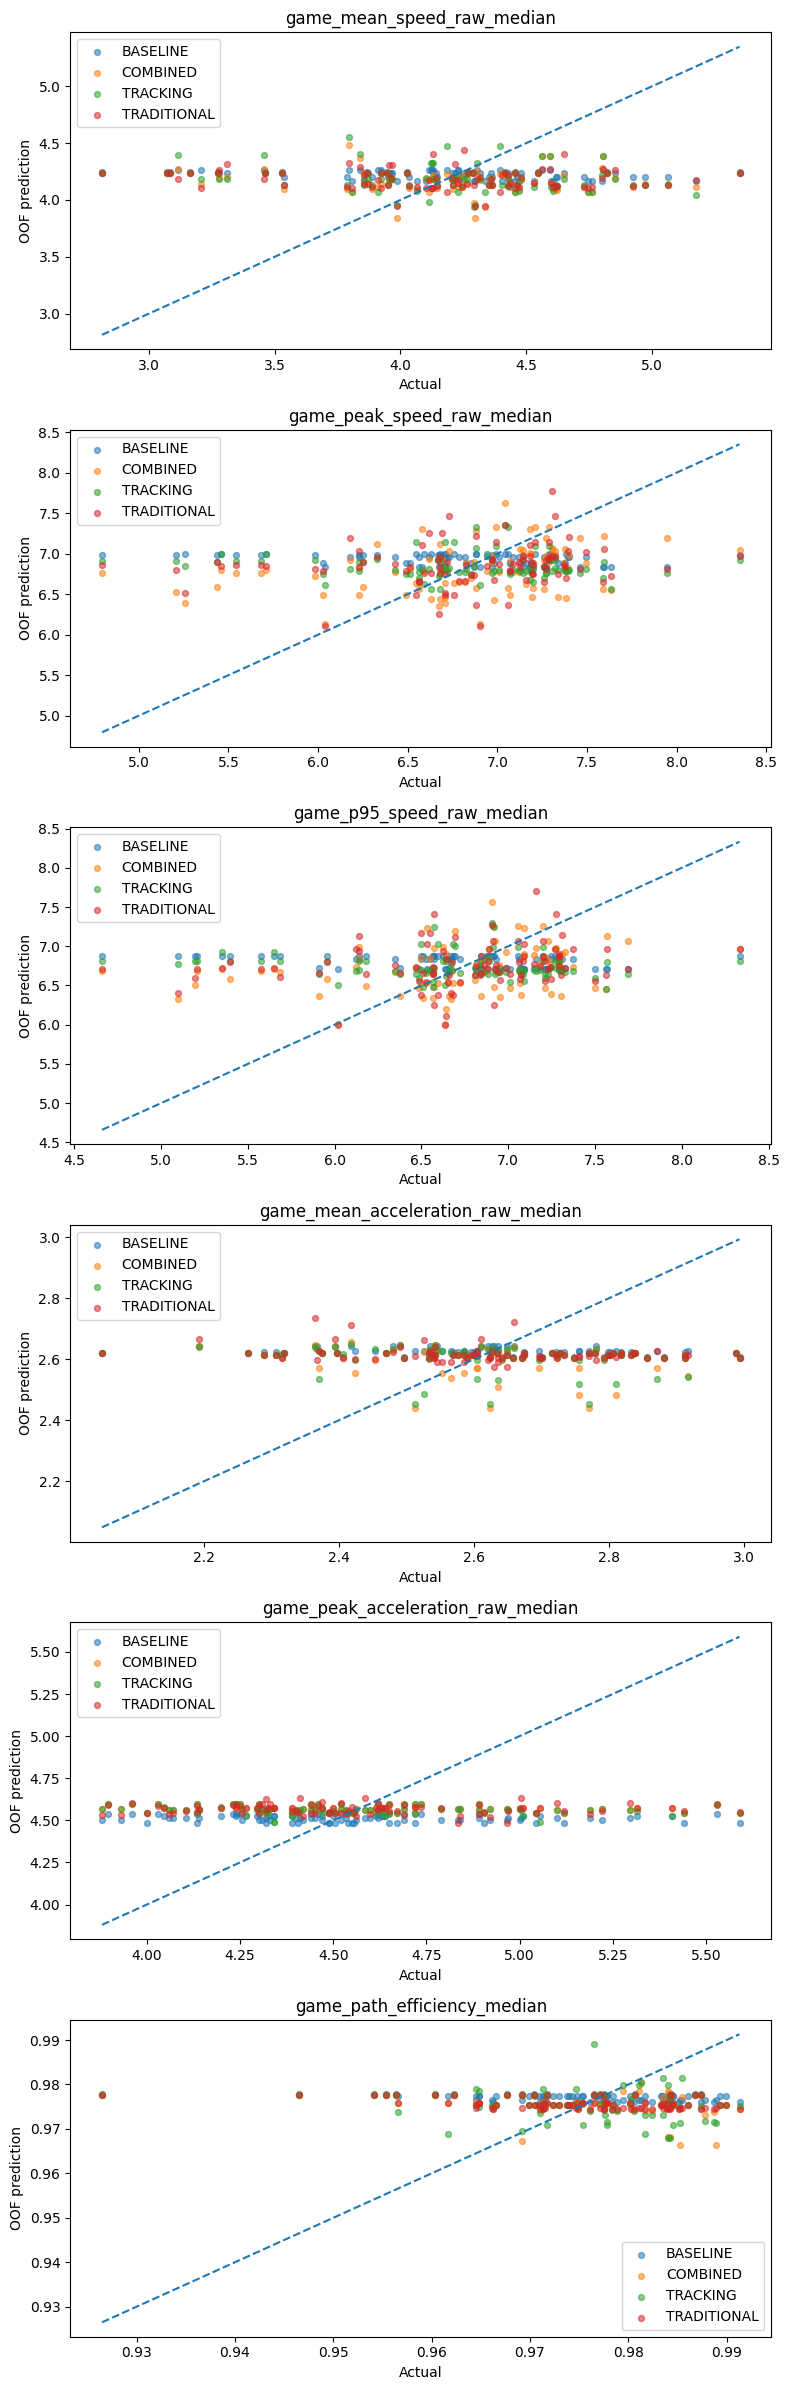

In [8]:
def safe_corr(a, b, method="pearson"):
    z = pd.DataFrame({"a": a, "b": b}).dropna()
    if len(z) < 3 or z.a.nunique() < 2 or z.b.nunique() < 2:
        return np.nan
    return z.a.corr(z.b, method=method)

calibration_rows = []
for (outcome, model), g in oof.groupby(["outcome","model"]):
    z = g[["actual","predicted"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(z) == 0:
        continue
    slope = np.polyfit(z["actual"], z["predicted"], 1)[0] if z.actual.nunique()>1 else np.nan
    intercept = np.polyfit(z["actual"], z["predicted"], 1)[1] if z.actual.nunique()>1 else np.nan
    actual_sd, pred_sd = z.actual.std(), z.predicted.std()
    calibration_rows.append({
        "outcome": outcome, "model": model, "n_player_seasons": len(z),
        "receivers": g.nfl_id.nunique(),
        "mae": np.mean(np.abs(z.actual-z.predicted)),
        "rmse": np.sqrt(np.mean((z.actual-z.predicted)**2)),
        "r2": 1 - np.sum((z.actual-z.predicted)**2)/np.sum((z.actual-z.actual.mean())**2) if z.actual.nunique()>1 else np.nan,
        "pearson_r": safe_corr(z.actual,z.predicted),
        "spearman_rho": safe_corr(z.actual,z.predicted,"spearman"),
        "calibration_slope_pred_on_actual": slope,
        "calibration_intercept": intercept,
        "actual_sd": actual_sd, "prediction_sd": pred_sd,
        "prediction_to_actual_sd_ratio": pred_sd/actual_sd if actual_sd and np.isfinite(actual_sd) else np.nan,
        "mean_actual": z.actual.mean(), "mean_prediction": z.predicted.mean()
    })
calibration = pd.DataFrame(calibration_rows)
display(calibration)
calibration.to_csv(OUT_DIR / "prediction_calibration_and_shrinkage.csv", index=False)

fig, axes = plt.subplots(len(available_outcomes), 1, figsize=(8, 4*len(available_outcomes)))
if len(available_outcomes) == 1: axes = [axes]
for ax, outcome in zip(axes, available_outcomes):
    gg = oof[oof.outcome == outcome]
    for model, gm in gg.groupby("model"):
        z = gm[["actual","predicted"]].dropna()
        ax.scatter(z.actual, z.predicted, s=18, alpha=.55, label=model)
    vals = pd.concat([gg.actual, gg.predicted]).dropna()
    if len(vals):
        lo, hi = vals.min(), vals.max()
        ax.plot([lo,hi],[lo,hi], linestyle="--")
    ax.set_title(outcome)
    ax.set_xlabel("Actual")
    ax.set_ylabel("OOF prediction")
    ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "oof_actual_vs_predicted.png", dpi=160)
plt.show()

## 9. Residual diagnostics and receiver-level error concentration

In [9]:
oof_diag = oof.copy()
oof_diag["actual"] = pd.to_numeric(oof_diag.actual, errors="coerce")
oof_diag["predicted"] = pd.to_numeric(oof_diag.predicted, errors="coerce")
oof_diag["residual"] = oof_diag.actual - oof_diag.predicted
oof_diag["absolute_error"] = oof_diag.residual.abs()
oof_diag["squared_error"] = oof_diag.residual ** 2

residual_rows = []
for (outcome, model, cohort), g in oof_diag.groupby(["outcome","model","draft_year"]):
    z = g.dropna(subset=["residual"])
    residual_rows.append({
        "outcome": outcome, "model": model, "draft_year": cohort,
        "rows": len(z), "receivers": z.nfl_id.nunique(),
        "mean_residual": z.residual.mean(),
        "median_residual": z.residual.median(),
        "mae": z.absolute_error.mean(),
        "rmse": np.sqrt(z.squared_error.mean()),
        "p90_absolute_error": z.absolute_error.quantile(.90)
    })
residual_by_cohort = pd.DataFrame(residual_rows)
display(residual_by_cohort)
residual_by_cohort.to_csv(OUT_DIR / "residual_diagnostics_by_cohort.csv", index=False)

receiver_error = (oof_diag.groupby(["outcome","model","nfl_id"])
                 .agg(rows=("absolute_error","size"), mae=("absolute_error","mean"),
                      mean_residual=("residual","mean"))
                 .reset_index())
receiver_error.to_csv(OUT_DIR / "receiver_level_prediction_errors.csv", index=False)

tail = (receiver_error.groupby(["outcome","model"])
        .apply(lambda g: pd.Series({
            "receivers": g.nfl_id.nunique(),
            "median_receiver_mae": g.mae.median(),
            "p90_receiver_mae": g.mae.quantile(.90),
            "worst_receiver_mae": g.mae.max()
        }), include_groups=False).reset_index())
display(tail)
tail.to_csv(OUT_DIR / "receiver_error_concentration.csv", index=False)

,outcome,model,draft_year,rows,receivers,mean_residual,median_residual,mae,rmse,p90_absolute_error
0,game_mean_acceleration_raw_median,BASELINE,2023,45,20,0.014222,0.034533,0.167292,0.210258,0.330350
1,game_mean_acceleration_raw_median,BASELINE,2024,34,20,-0.004059,-0.013697,0.113109,0.142525,0.265773
2,game_mean_acceleration_raw_median,BASELINE,2025,14,14,-0.078283,-0.069962,0.147271,0.181358,0.290357
3,game_mean_acceleration_raw_median,COMBINED,2023,45,20,0.040895,0.073441,0.179731,0.222021,0.362783
4,game_mean_acceleration_raw_median,COMBINED,2024,34,20,0.016179,0.013697,0.117723,0.155089,0.281713
...,...,...,...,...,...,...,...,...,...,...
67,game_peak_speed_raw_median,TRACKING,2024,34,20,-0.137707,-0.085390,0.508344,0.661682,1.224933
68,game_peak_speed_raw_median,TRACKING,2025,14,14,0.087930,0.202420,0.430505,0.496334,0.683054
69,game_peak_speed_raw_median,TRADITIONAL,2023,45,20,0.050754,0.160583,0.440416,0.621422,1.161120
70,game_peak_speed_raw_median,TRADITIONAL,2024,34,20,-0.127261,-0.003460,0.546887,0.678575,1.101605


,outcome,model,receivers,median_receiver_mae,p90_receiver_mae,worst_receiver_mae
0,game_mean_acceleration_raw_median,BASELINE,54.0,0.145112,0.269268,0.384147
1,game_mean_acceleration_raw_median,COMBINED,54.0,0.142381,0.295229,0.382681
2,game_mean_acceleration_raw_median,TRACKING,54.0,0.148463,0.272650,0.382708
3,game_mean_acceleration_raw_median,TRADITIONAL,54.0,0.145215,0.299387,0.382682
4,game_mean_speed_raw_median,BASELINE,54.0,0.279280,0.883691,1.225597
5,game_mean_speed_raw_median,COMBINED,54.0,0.314343,0.863634,1.213787
6,game_mean_speed_raw_median,TRACKING,54.0,0.312069,0.846617,1.213822
7,game_mean_speed_raw_median,TRADITIONAL,54.0,0.335269,0.870604,1.213795
8,game_p95_speed_raw_median,BASELINE,54.0,0.352292,0.950513,1.729500
9,game_p95_speed_raw_median,COMBINED,54.0,0.374137,0.891959,1.531632


## 10. Ridge alpha selection and boundary diagnostics

In [10]:
print("Inner tuning columns:", inner.columns.tolist())
print("Alpha diagnostics columns:", alpha_diag.columns.tolist())

# Identify likely columns without assuming a specific spelling.
def find_col(frame, candidates):
    lower = {c.lower(): c for c in frame.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    for c in frame.columns:
        if any(token in c.lower() for token in candidates):
            return c
    return None

alpha_col = find_col(inner, ["alpha"])
outcome_col = find_col(inner, ["outcome"])
model_col = find_col(inner, ["model"])
fold_col = find_col(inner, ["outer_fold", "fold"])
score_col = find_col(inner, ["mean_inner_mae", "mean_validation_mae", "mean_mae", "mae"])

print({"outcome": outcome_col, "model": model_col, "fold": fold_col,
       "alpha": alpha_col, "score": score_col})

if all([alpha_col, outcome_col, model_col, fold_col, score_col]):
    inner_clean = inner.copy()
    for c in [alpha_col, score_col]:
        inner_clean[c] = pd.to_numeric(inner_clean[c], errors="coerce")
    inner_clean = inner_clean.dropna(subset=[alpha_col, score_col])
    best = (inner_clean.sort_values(score_col)
            .groupby([outcome_col, model_col, fold_col], as_index=False).first())
    max_alpha = inner_clean.groupby([outcome_col, model_col, fold_col])[alpha_col].max().rename("grid_max_alpha")
    best = best.merge(max_alpha.reset_index(), on=[outcome_col,model_col,fold_col], how="left")
    best["selected_at_upper_boundary"] = np.isclose(best[alpha_col], best["grid_max_alpha"])
    display(best)
    best.to_csv(OUT_DIR / "selected_alpha_by_outer_fold_reconstructed.csv", index=False)

    alpha_summary = (best.groupby([outcome_col,model_col])
                     .agg(folds=("selected_at_upper_boundary","size"),
                          median_selected_alpha=(alpha_col,"median"),
                          boundary_folds=("selected_at_upper_boundary","sum"))
                     .reset_index())
    alpha_summary["boundary_fold_pct"] = 100*alpha_summary.boundary_folds/alpha_summary.folds
    display(alpha_summary)
    alpha_summary.to_csv(OUT_DIR / "alpha_selection_summary.csv", index=False)
else:
    print("Could not safely infer the inner-tuning schema. No alpha reconstruction performed.")
    print("Inspect inner_tuning_results.csv columns and update the mapping explicitly if needed.")

Inner tuning columns: ['outcome', 'model', 'outer_fold', 'best_alpha', 'inner_best_mae', 'train_rows', 'test_rows', 'train_players', 'test_players', 'alpha_at_grid_boundary']
Alpha diagnostics columns: ['outcome', 'model', 'folds', 'median_alpha', 'min_alpha', 'max_alpha', 'boundary_alpha_folds']
{'outcome': 'outcome', 'model': 'model', 'fold': 'outer_fold', 'alpha': 'best_alpha', 'score': 'inner_best_mae'}


,outcome,model,outer_fold,best_alpha,inner_best_mae,train_rows,test_rows,train_players,test_players,alpha_at_grid_boundary,grid_max_alpha,selected_at_upper_boundary
0,game_mean_acceleration_raw_median,COMBINED,1,10.0,0.144678,74,19,43,11,False,10.0,True
1,game_mean_acceleration_raw_median,COMBINED,2,100000.0,0.143396,74,19,43,11,True,100000.0,True
2,game_mean_acceleration_raw_median,COMBINED,3,100000.0,0.147836,74,19,43,11,True,100000.0,True
3,game_mean_acceleration_raw_median,COMBINED,4,1000.0,0.145339,75,18,44,10,False,1000.0,True
4,game_mean_acceleration_raw_median,COMBINED,5,100000.0,0.129347,75,18,43,11,True,100000.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
85,game_peak_speed_raw_median,TRADITIONAL,1,10.0,0.437468,74,19,43,11,False,10.0,True
86,game_peak_speed_raw_median,TRADITIONAL,2,10.0,0.449843,74,19,43,11,False,10.0,True
87,game_peak_speed_raw_median,TRADITIONAL,3,10.0,0.433434,74,19,43,11,False,10.0,True
88,game_peak_speed_raw_median,TRADITIONAL,4,100.0,0.367305,75,18,44,10,False,100.0,True


,outcome,model,folds,median_selected_alpha,boundary_folds,boundary_fold_pct
0,game_mean_acceleration_raw_median,COMBINED,5,100000.0,5,100.0
1,game_mean_acceleration_raw_median,TRACKING,5,1000.0,5,100.0
2,game_mean_acceleration_raw_median,TRADITIONAL,5,100000.0,5,100.0
3,game_mean_speed_raw_median,COMBINED,5,1000.0,5,100.0
4,game_mean_speed_raw_median,TRACKING,5,100000.0,5,100.0
5,game_mean_speed_raw_median,TRADITIONAL,5,100.0,5,100.0
6,game_p95_speed_raw_median,COMBINED,5,10.0,5,100.0
7,game_p95_speed_raw_median,TRACKING,5,1000.0,5,100.0
8,game_p95_speed_raw_median,TRADITIONAL,5,10.0,5,100.0
9,game_path_efficiency_median,COMBINED,5,100000.0,5,100.0


## 11. LOCO performance review

In [11]:
display(loco_metrics.head(20))
loco_metrics.to_csv(OUT_DIR / "loco_metrics_snapshot.csv", index=False)

if {"outcome","model","held_out_draft_year"}.issubset(loco_metrics.columns):
    loco_keys = ["outcome","model","held_out_draft_year"]
    loco_metrics.groupby("outcome").size().to_csv(OUT_DIR / "loco_cohort_counts.csv")
else:
    print("LOCO metric column names differ from expected; inspect the table above.")

,outcome,model,held_out_draft_year,n,mae,rmse,r2,spearman
0,game_mean_acceleration_raw_median,BASELINE,2023,45,0.169187,0.211680,-0.039524,NaN
1,game_mean_acceleration_raw_median,BASELINE,2024,34,0.108006,0.137716,-0.000482,NaN
2,game_mean_acceleration_raw_median,BASELINE,2025,14,0.150548,0.181506,-0.266422,NaN
3,game_mean_acceleration_raw_median,COMBINED,2023,45,0.184433,0.223885,-0.162856,0.034243
4,game_mean_acceleration_raw_median,COMBINED,2024,34,0.108406,0.137773,-0.001308,-0.050168
5,game_mean_acceleration_raw_median,COMBINED,2025,14,0.150813,0.181931,-0.272348,0.112088
6,game_mean_acceleration_raw_median,TRACKING,2023,45,0.167578,0.210335,-0.026354,0.230199
7,game_mean_acceleration_raw_median,TRACKING,2024,34,0.108402,0.137771,-0.001274,0.007342
8,game_mean_acceleration_raw_median,TRACKING,2025,14,0.150814,0.181933,-0.272383,0.147253
9,game_mean_acceleration_raw_median,TRADITIONAL,2023,45,0.172289,0.213936,-0.061800,-0.063801


## 12. Diagnostic interpretation checklist

In [12]:
interpretation = pd.DataFrame([
    ["Predictor redundancy", "Large absolute Spearman correlations indicate overlapping information; they do not by themselves prove harmful multicollinearity."],
    ["Low predictor variation", "Very low variation or few unique values can limit the information available to a model."],
    ["Prediction shrinkage", "A prediction/actual SD ratio far below 1 indicates compressed predictions; interpret alongside calibration slope and correlation."],
    ["Calibration", "A slope far below 1 indicates predictions vary less than actual outcomes; a slope near 1 is not sufficient without low error."],
    ["Receiver error concentration", "A high gap between median and 90th-percentile receiver MAE indicates performance may be uneven across players."],
    ["Cohort instability", "Differences across draft cohorts are descriptive, especially with the 2025 held-out cohort of 14 receivers."],
    ["Alpha boundary", "Repeated selection of the largest alpha suggests the tested grid may not bracket the optimum or the predictors carry weak signal. It is not proof of a coding error."],
    ["No causal inference", "These observational predictions do not establish that Combine traits cause in-game movement performance."]
], columns=["diagnostic","interpretation"])
display(interpretation)
interpretation.to_csv(OUT_DIR / "interpretation_guide.csv", index=False)

,diagnostic,interpretation
0,Predictor redundancy,Large absolute Spearman correlations indicate ...
1,Low predictor variation,Very low variation or few unique values can li...
2,Prediction shrinkage,A prediction/actual SD ratio far below 1 indic...
3,Calibration,A slope far below 1 indicates predictions vary...
4,Receiver error concentration,A high gap between median and 90th-percentile ...
5,Cohort instability,Differences across draft cohorts are descripti...
6,Alpha boundary,Repeated selection of the largest alpha sugges...
7,No causal inference,These observational predictions do not establi...


## 13. Export manifest and final integrity checks

In [13]:
manifest = {
    "notebook": "08A_model_stability_signal_and_shrinkage_diagnostics",
    "dataset": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "dataset_sha256": sha,
    "rows": int(len(df)),
    "unique_receivers": int(df.nfl_id.nunique()),
    "oof_rows": int(len(oof)),
    "outcomes": available_outcomes,
    "predictors": available_features,
    "source_modeling_manifest": str(FILES["manifest"].relative_to(PROJECT_ROOT)),
    "diagnostic_scope": [
        "predictor_distributions", "predictor_correlations", "outcome_variation",
        "oof_coverage", "paired_sample_audit", "prediction_calibration_and_shrinkage",
        "residual_diagnostics", "receiver_error_concentration", "alpha_selection",
        "LOCO_review"
    ],
    "does_not_refit_primary_models": True,
    "does_not_overwrite_nested_ridge_outputs": True
}
with open(OUT_DIR / "model_stability_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

# Ensure source artifacts remain present and outputs have been written.
expected_outputs = [
    "predictor_distributions.csv", "predictor_spearman_correlations.csv",
    "outcome_variation.csv", "oof_coverage.csv",
    "oof_paired_sample_audit.csv", "prediction_calibration_and_shrinkage.csv",
    "residual_diagnostics_by_cohort.csv", "receiver_level_prediction_errors.csv",
    "receiver_error_concentration.csv", "interpretation_guide.csv",
    "model_stability_manifest.json"
]
missing_outputs = [x for x in expected_outputs if not (OUT_DIR/x).exists()]
assert not missing_outputs, missing_outputs
print("NOTEBOOK 08A COMPLETE")
print("Outputs:", OUT_DIR)
print("Core dataset SHA256:", sha)
print("Missing expected outputs:", missing_outputs)

NOTEBOOK 08A COMPLETE
Outputs: D:\PROJECTS\WR-MovementIQ\reports\model_stability
Core dataset SHA256: 02fbd802522973f7c4d100da57cd680f7bbfde6346a0431a7aa1fe5e25807c5c
Missing expected outputs: []
